Step 1 done — data loaded. Shape: (125973, 43)
Step 2 done — cleaned & encoded. Final shape: (125973, 122)

Step 3 done — model trained.
Accuracy : 0.9989680492161143
Precision: 0.9994024244493768
Recall   : 0.9983796691113764
F1-Score : 0.9988907849829352
Confusion Matrix:
 [[13462     7]
 [   19 11707]]


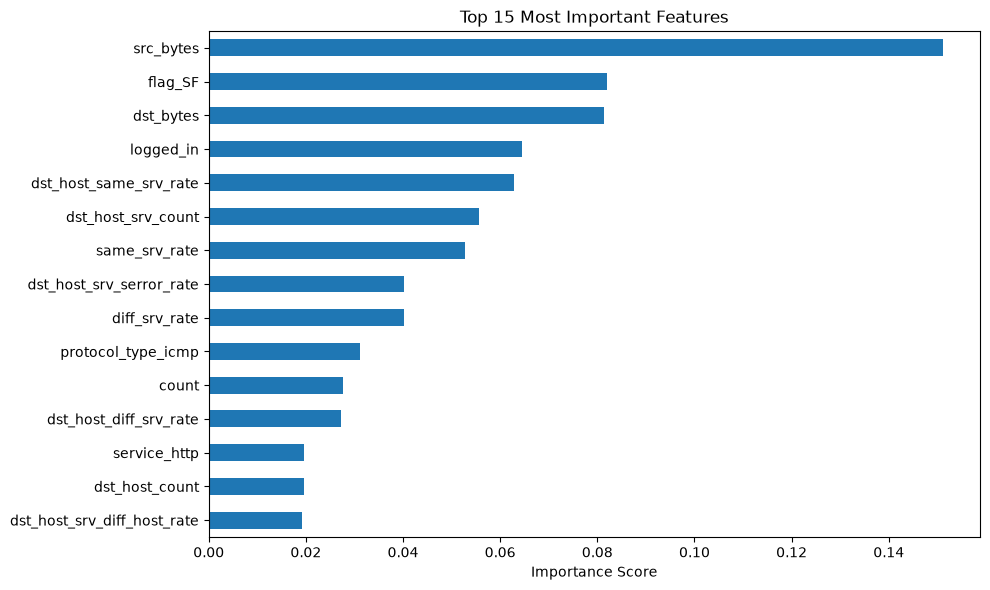


✅ Model and feature columns saved successfully!


In [12]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

# ---------- MILESTONE 1: Load the dataset ----------
columns = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty_level"
]

df = pd.read_csv("KDDTrain+.txt", header=None, names=columns)
print("Step 1 done — data loaded. Shape:", df.shape)

# ---------- MILESTONE 2: Clean & encode ----------
df['attack_type'] = df['label'].apply(lambda x: 'normal' if x == 'normal' else 'attack')
df = df.drop(['label', 'difficulty_level'], axis=1)
df = pd.get_dummies(df, columns=['protocol_type', 'service', 'flag'])

X = df.drop('attack_type', axis=1)
y = df['attack_type'].apply(lambda x: 0 if x == 'normal' else 1)
print("Step 2 done — cleaned & encoded. Final shape:", X.shape)

# ---------- MILESTONE 3: Train the model ----------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("\nStep 3 done — model trained.")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-Score :", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# ---------- MILESTONE 4: Feature importance ----------
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
importances.head(15).plot(kind='barh')
plt.gca().invert_yaxis()
plt.title("Top 15 Most Important Features")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

# ---------- SAVE MODEL FOR DASHBOARD ----------
joblib.dump(model, 'nids_model.pkl')
X.columns.to_series().to_csv('feature_columns.csv', index=False)
print("\n✅ Model and feature columns saved successfully!")